## MIST v2.5 evolutionary-track fitting with NUTS

Use the same observations and bounded age-prior configuration as `fit_track.ipynb`, with a MIST v2.5 track grid.
The fitting domain is initial mass 0.8–2.0 solar masses, initial FeH −0.75–0.5, and EEP 202–550; rotation is 0.4 and `afe=0`.
The grid-building command below covers the wider initial FeH range −1.0–0.5.

Run with this notebook directory (`examples/mistfit`) as the working directory and a fresh kernel for the parallel-chain configuration.
Install this checkout in that kernel's environment first, for example with `python -m pip install -e ../..` from this directory.
All example paths below are relative to this directory.

### Build the grid with structural columns once

The grid includes all 66 native non-isotope columns, in addition to the existing fitting fields and photometry.
Skip this step if the NPZ below already exists. Otherwise, run this command in a terminal from this notebook directory, using its Python environment:

```bash
python -m jaxstar.mistfit.mistgrid.create_tracks \
  grid_structure.npz \
  --version 2.5 --rotation 0.4 --afe 0 \
  --mass-range 0.8 2. --eep-range 202 550 \
  --feh-range -1.0 0.5 --include-structure
```

`--include-structure` retains all 66 native non-isotope columns, including convective-envelope boundaries, the three convective turnover times, total moment of inertia, and the apsidal constant `k2`. The original column names and units are preserved; the 102 surface/central isotope-abundance columns are excluded.
These columns become available through `MistModel` for postprocessing, as shown at the end of this notebook. They do not automatically enter the likelihood or the default NUTS outputs. Without this flag, the builder writes the compact fitting grid.

Cached source archives are reused; missing archives download automatically. Each selected FeH archive is downloaded in full even for a small mass/EEP region.
To reuse another existing cache, configure `JAXSTAR_MIST_RAW_DIR` in your shell or append `--raw-cache-dir path/to/cache` to the command. Use `--local-dir path/to/archives` to import previously downloaded archives, or `--offline` to require cached/local inputs.
The NPZ is saved at the relative path used below. To replace an existing output explicitly, add `--overwrite`. See the [grid guide](../../docs/mistgrid.md).

In [1]:
from datetime import datetime
from pathlib import Path
import warnings

# Keep warning messages in saved outputs without local directory names.
def _format_warning(message, category, filename, lineno, line=None):
    return f"{Path(filename).name}:{lineno}: {category.__name__}: {message}\n"

warnings.formatwarning = _format_warning

import numpyro

num_chains = 4
numpyro.set_host_device_count(num_chains)  # before JAX initializes devices

import jax
jax.config.update("jax_enable_x64", True)

from jaxstar.mistfit import MistModel, MistFit

In [2]:
grid_path = Path("grid_structure.npz")
model = MistModel.from_tracks(grid_path)
{key: model.metadata[key] for key in ("mist_version", "rotation", "afe", "photometry")}

{'mist_version': '2.5', 'rotation': 0.4, 'afe': 0.0, 'photometry': 'UBVRIplus'}

In [3]:
observations = {
    "teff": (5719, 110.),
    "feh": (-0.12, 0.1),
    "kmag": (8.843, 0.014),
    "parallax": (7.27355841, 3.008e-2),
}

# Multimodal example; pass observations2 to MistFit below to try it.
observations2 = {
    "teff": (5949, 104),
    "feh": (0.237, 0.102),
    "kmag": (11.660, 0.0245),
    "parallax": (0.873, 0.013),
}

mf = MistFit(model=model, observations=observations)

### NUTS

The NUTS call below uses the configured mass, initial FeH and EEP bounds. Age is an output; `linear_age=True` uses the centered `dt/dEEP` field for the age prior. The soft upper age bound is 13.8 Gyr with width 0.1 Gyr.
The seed, four chains and sampler defaults match `fit_track.ipynb` (5,000 warmup steps and 5,000 retained draws per chain).

`run_nuts` finds its starting point internally at fixed observed FeH (zero if absent) and inverse observed parallax. NUTS then samples all latent parameters. The missed-mode check below performs a separate FeH scan after sampling, using the scientific options recorded with this run.

In [4]:
model_kwargs = {
    "linear_age": True,
    "age_max": 13.8, "age_bound_width": 0.1,
    "massmin": 0.8, "massmax": 2.0,
    "fmin": -0.75, "fmax": 0.5,
    "eepmin": 202., "eepmax": 550.,
}

mcmc = mf.run_nuts(
    jax.random.PRNGKey(0),
    num_chains=num_chains,
    model_kwargs=model_kwargs,
    output_keys=("kmag_abs",),
)

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

In [5]:
mcmc.print_summary()


                mean       std    median      5.0%     95.0%     n_eff     r_hat
  distance      0.14      0.00      0.14      0.14      0.14  10370.77      1.00
       eep    376.89     14.30    378.93    357.19    398.20   2381.04      1.00
  feh_init     -0.02      0.09     -0.02     -0.16      0.12   6636.24      1.00
      mass      0.95      0.05      0.94      0.87      1.02   3169.77      1.00

Number of divergences: 0


In [6]:
idata = mf.to_inference_data(mcmc)
run_name = datetime.now().strftime("run_%Y%m%d_%H%M%S_%f")
result_dir = Path("results/track_nuts_v25") / run_name
_ = mf.save_result(idata, result_dir)
result_dir

diagnostics.py:90: RuntimeWarning: invalid value encountered in scalar divide
diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide


PosixPath('results/track_nuts_v25/run_20261017_170712_562794')

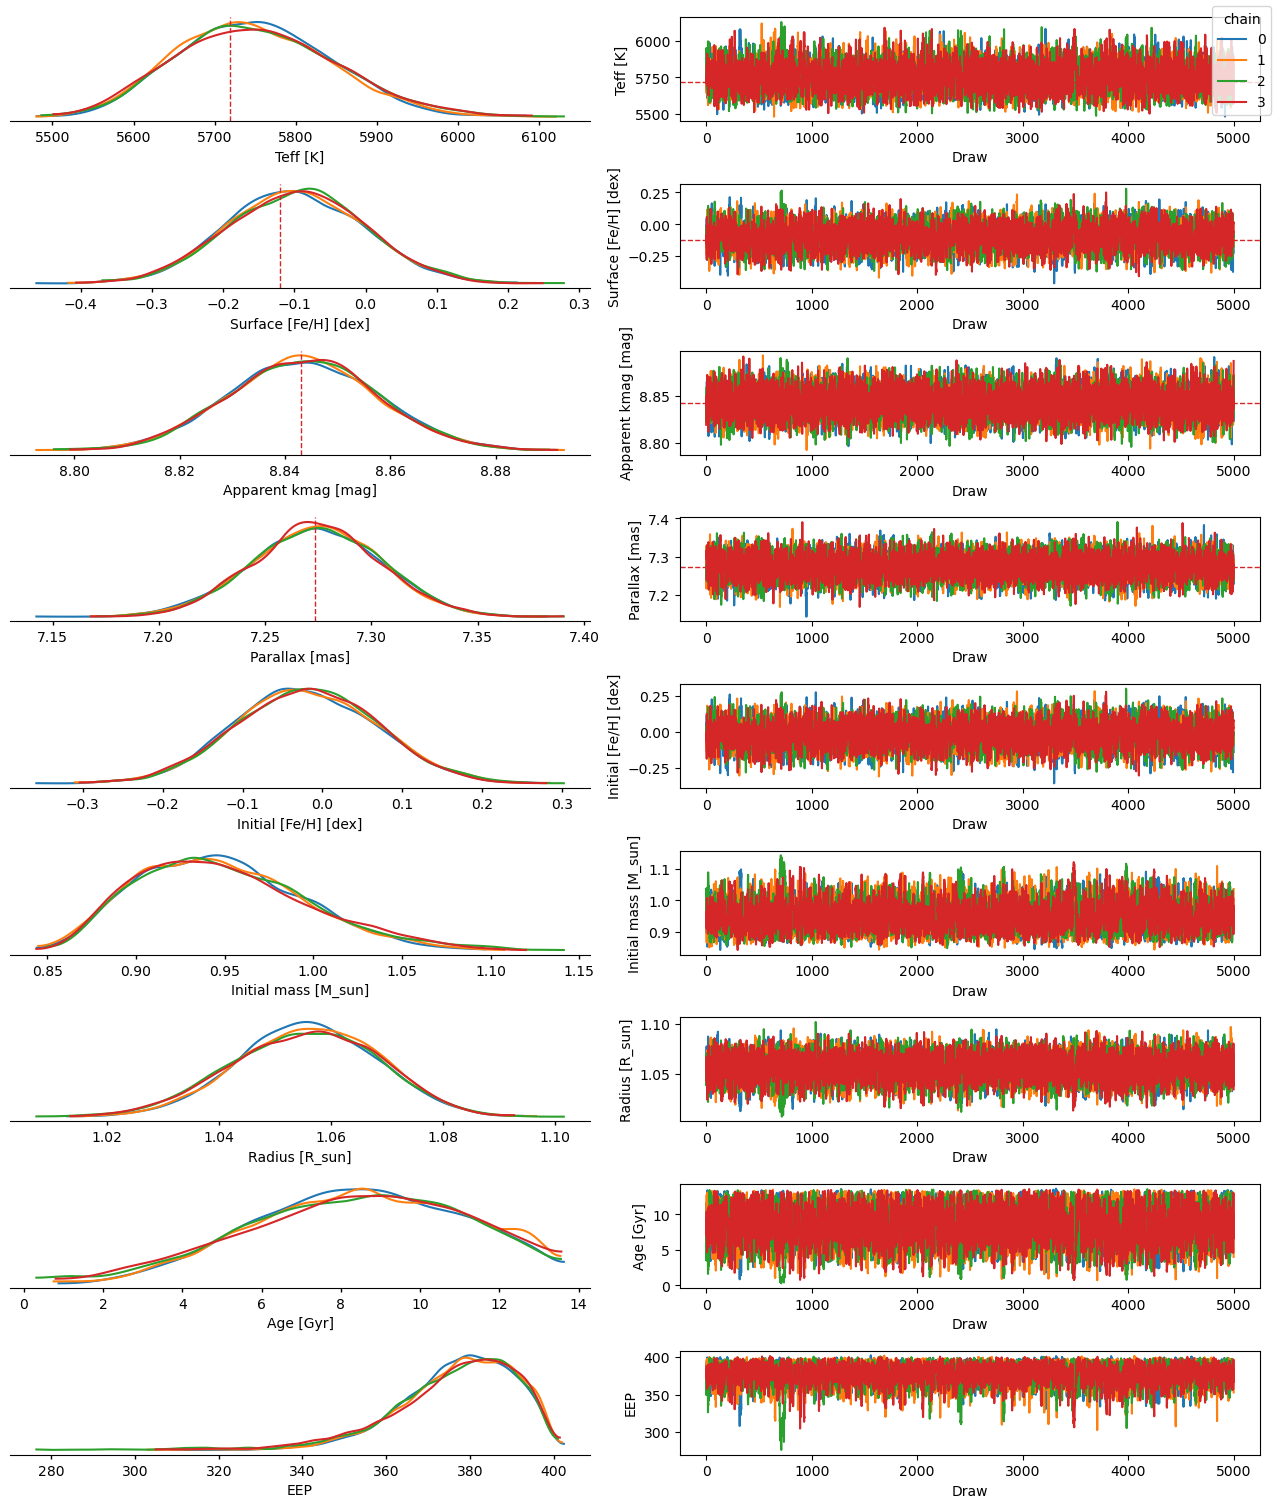

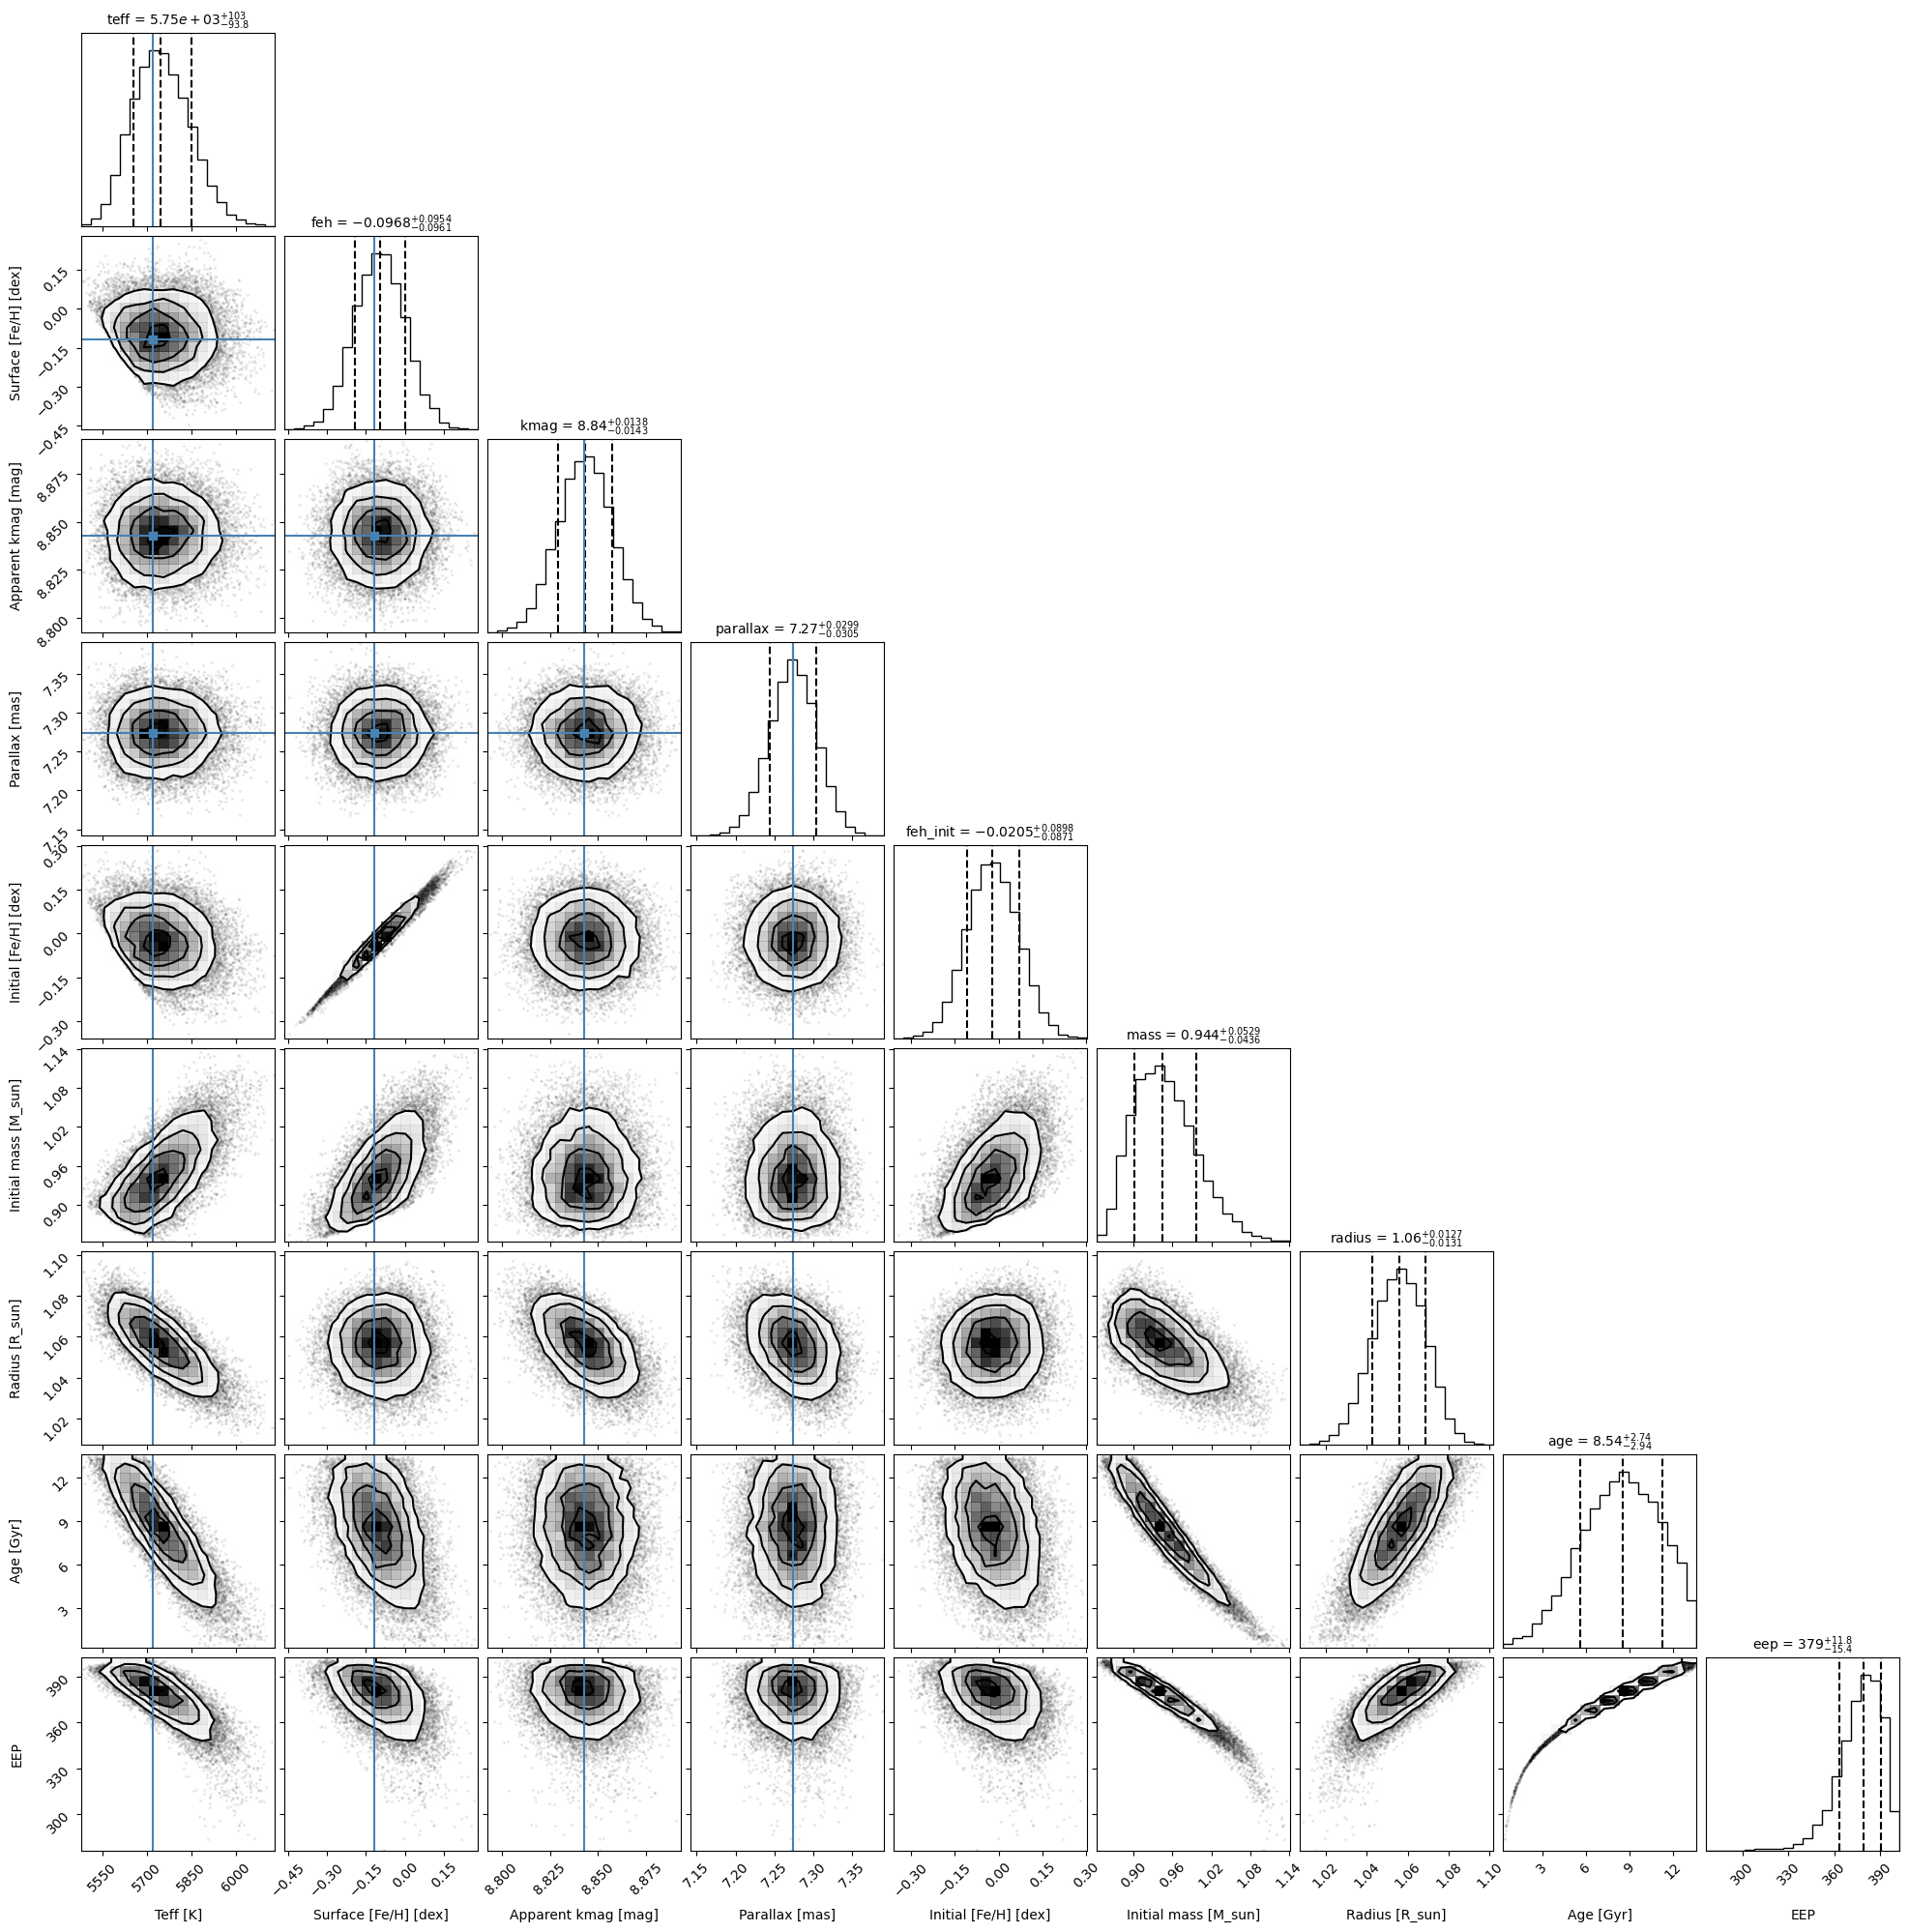

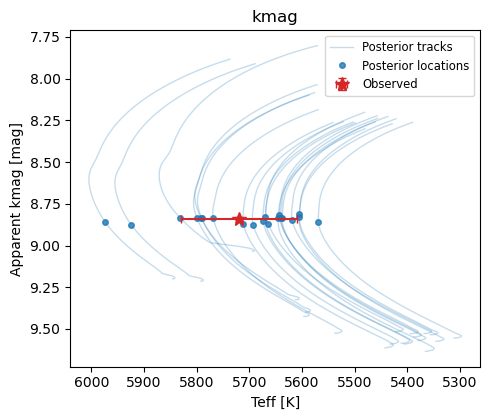

In [7]:
outkeys = [*observations, "feh_init", "mass", "radius", "age", "eep"]
figures = mf.plot_diagnostics(idata, keys=outkeys, output_dir=result_dir)

### Potentially missed modes

Check for candidate regions that NUTS may have missed using a separate 0.1-dex FeH scan. Red crosses mark flagged regions; a flag suggests a possible missed mode, not a confirmed one. If a region is flagged, try [nested sampling](#nested-sampling) below and compare its posterior with NUTS.

With the default `observations`, this scan shows no evidence of multiple modes. For a multimodal example, pass `observations2` to `MistFit` above.

`mode_check["grid_search"]` retains the scan. Use `recheck_missed_modes` to adjust the threshold and visit criteria without rescanning. See the [diagnostic guide](../../docs/mistfit.md#potentially-missed-modes) for definitions and limitations.

In [8]:
from jaxstar.mistfit import recheck_missed_modes, plot_missed_modes

mode_check = mf.check_missed_modes(mcmc, feh_step=0.1)

# Re-run this to adjust the diagnostic settings without rescanning.
'''
mode_check = recheck_missed_modes(
    mode_check,
    threshold=5., min_samples=5, neighbor_cells=1,
    max_unvisited_fraction=0.1,  # flag if more than 10% of candidate cells are unvisited
)
'''

'\nmode_check = recheck_missed_modes(\n    mode_check,\n    threshold=5., min_samples=5, neighbor_cells=1,\n    max_unvisited_fraction=0.1,  # flag if more than 10% of candidate cells are unvisited\n)\n'

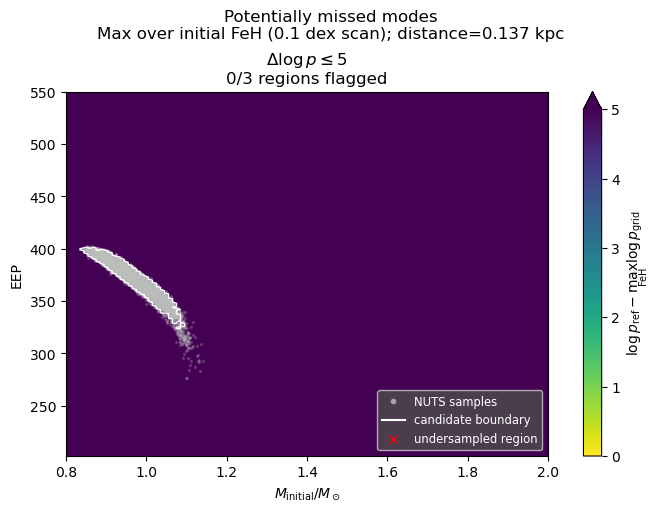

In [9]:
mode_figure = plot_missed_modes(mode_check)
mode_figure.savefig(result_dir / "missed_modes.png", dpi=150)

### Compare with the saved MIST v1.2 NUTS posterior

Load `results/track_nuts` from `fit_track.ipynb` and the v2.5 run saved above.
Use the same variables and corner style as the preceding plot, with common
axis ranges for both posteriors. Blue is v1.2; orange is v2.5. Diagonal titles
show the v2.5 median and 16th/84th percentiles. The observed reference lines
are shared. The comparison is saved as `corner_v12_v25.png` in `result_dir`.


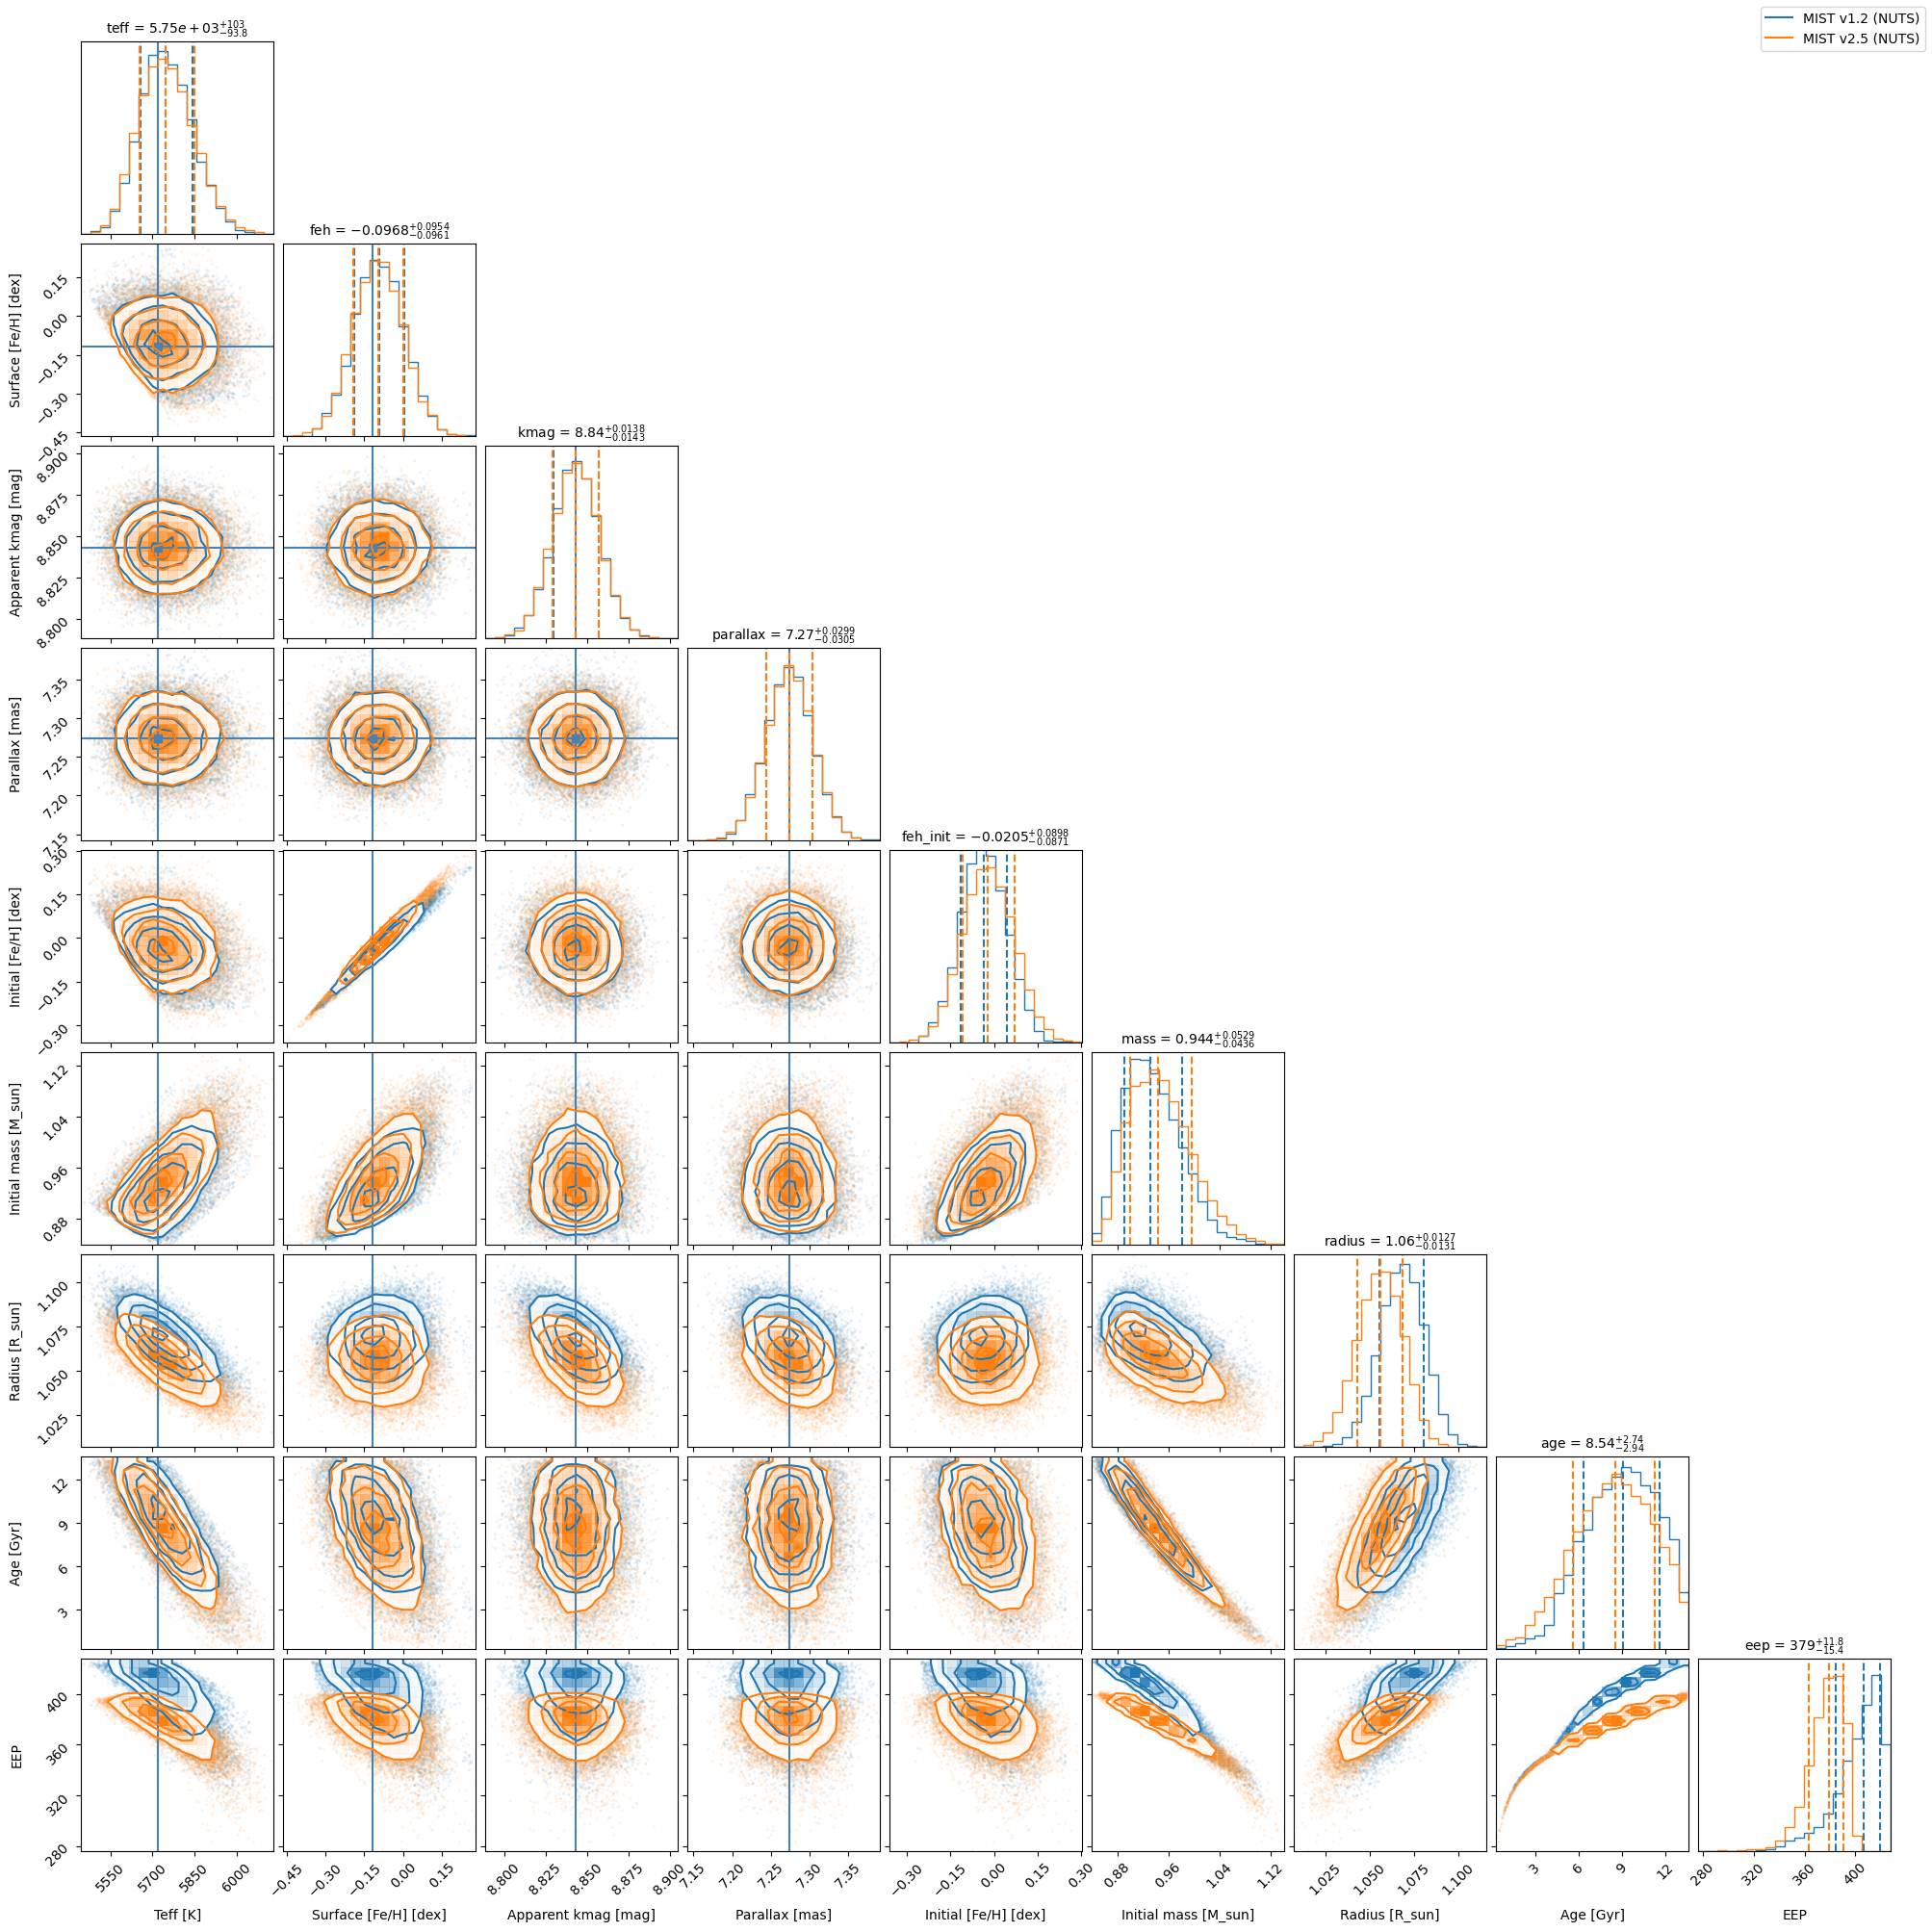

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from jaxstar.mistfit import load_result, plot_corner

idata_v12 = load_result(Path("results/track_nuts"))
idata_v25 = load_result(result_dir)

# Common limits and histogram bins include both saved posteriors.
corner_ranges = []
for key in outkeys:
    values = np.concatenate([
        idata_v12.posterior[key].values.ravel(),
        idata_v25.posterior[key].values.ravel(),
    ])
    lo, hi = float(values.min()), float(values.max())
    if lo == hi:
        width = max(abs(lo), 1.) * 1e-3
        lo, hi = lo - width, hi + width
    corner_ranges.append((lo, hi))

corner_comparison = plot_corner(
    idata_v12, keys=outkeys, color="C0", range=corner_ranges,
)
corner_comparison = plot_corner(
    idata_v25, keys=outkeys, color="C1", range=corner_ranges,
    fig=corner_comparison, show_observations=False,
)
corner_comparison.legend(
    handles=[
        Line2D([], [], color="C0", label="MIST v1.2 (NUTS)"),
        Line2D([], [], color="C1", label="MIST v2.5 (NUTS)"),
    ],
    loc="upper right",
)
comparison_path = result_dir / "corner_v12_v25.png"
corner_comparison.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()


### Structural quantities from the fitted posterior

Use `mf.physical_model` and `idata` above to compute all 66 native columns in `structure_samples`, then select six quantities for the corner plot: envelope thickness, envelope mass, local turnover time one mixing length above the envelope base, global turnover time, total moment of inertia, and the apsidal constant k2. Turnover times are shown in days and moment of inertia in units of 10^53 g cm². Nonfinite or nonpositive diagnostics are excluded together from the corner plot.


See the [native-column reference](../../docs/mistgrid-columns.md) for the full list of 66 columns, their contents and units.


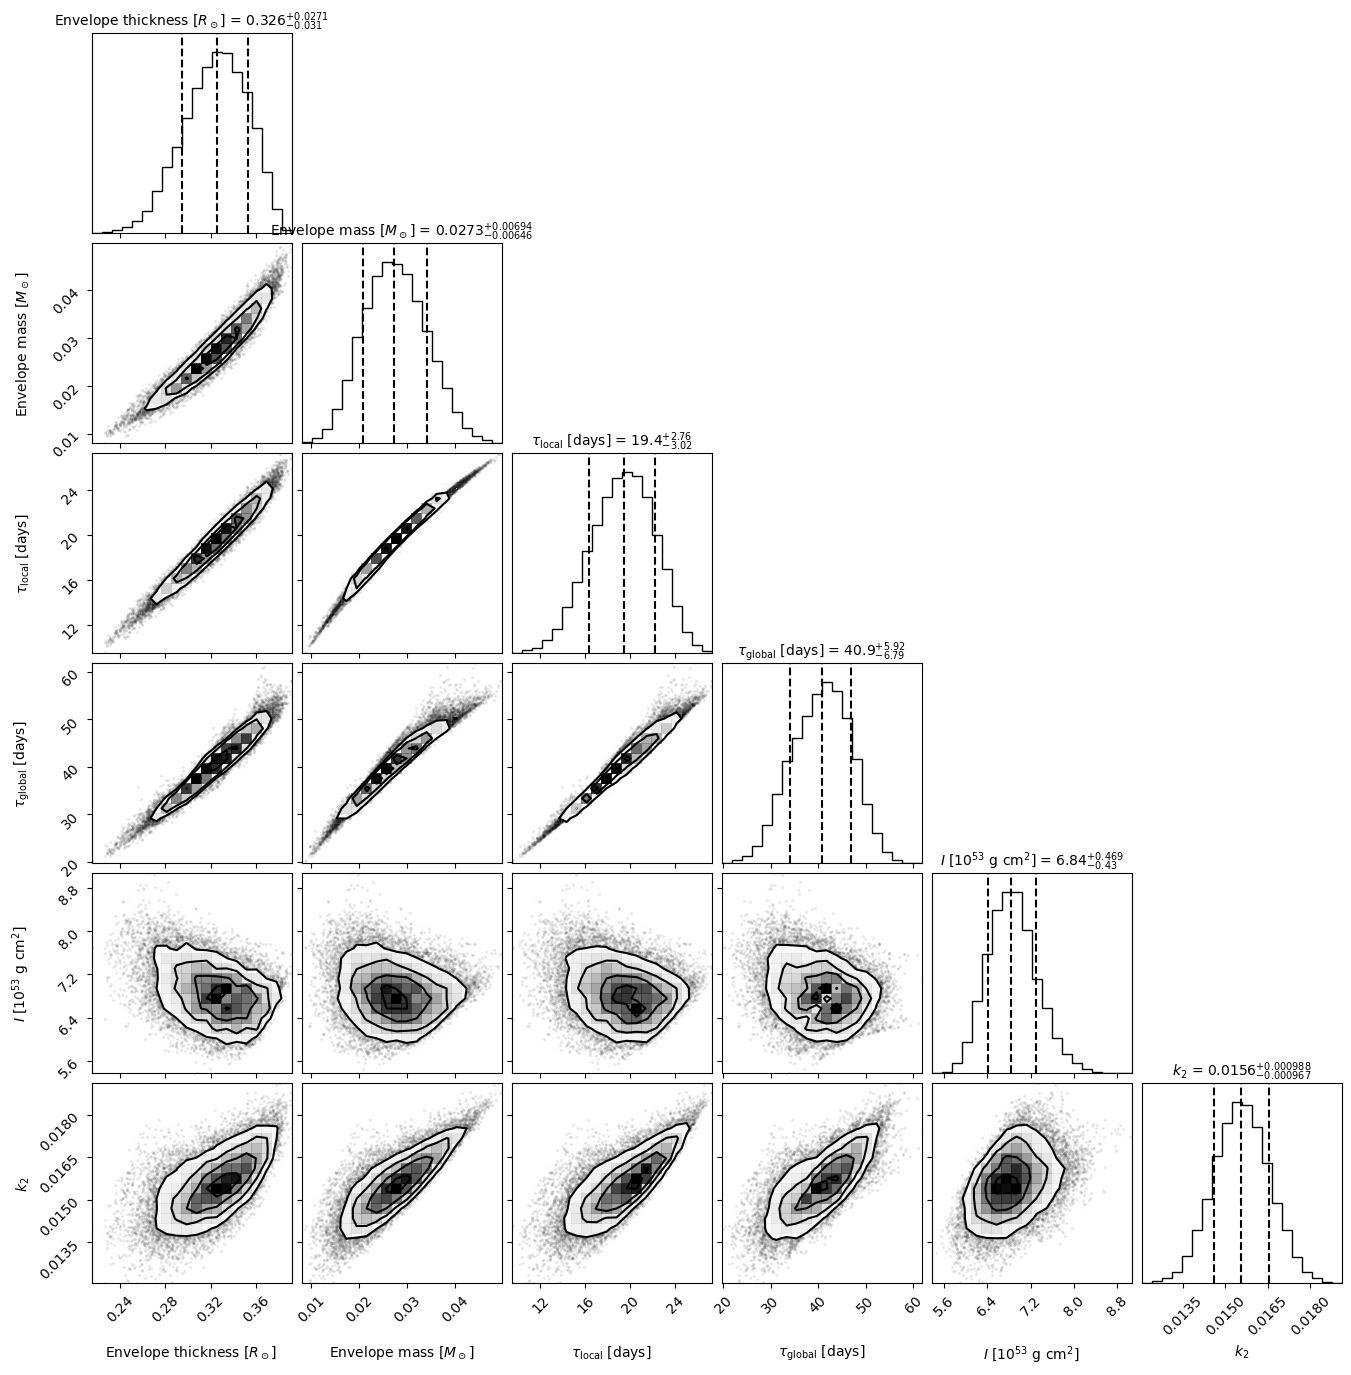

In [11]:
import corner
import numpy as np
import matplotlib.pyplot as plt

posterior = idata.posterior
# Predict all 66 native columns for the posterior samples.
structure_samples = mf.physical_model(
    {
        "mass_init": posterior["mass"].values,
        "feh_init": posterior["feh_init"].values,
        "eep": posterior["eep"].values,
    },
    keys=tuple(mf.physical_model.metadata["native_columns"]),
)

# Select six quantities for the corner plot.
p = structure_samples
corner_samples = np.column_stack([
    np.asarray(value).ravel() for value in (
        p["conv_env_top_radius"] - p["conv_env_bot_radius"],
        p["conv_env_top_mass"] - p["conv_env_bot_mass"],
        p["conv_env_turnover_time_l_t"] / 86400.,
        p["conv_env_turnover_time_g"] / 86400.,
        p["total_moment_of_inertia"] / 1e53,
        p["apsidal_constant_k2"],
    )
])
# Exclude unsupported predictions and absent-envelope zeros from the plot.
valid = np.all(np.isfinite(corner_samples) & (corner_samples > 0), axis=1)
if not valid.all():
    print(f"Corner uses {valid.sum()} / {len(valid)} posterior draws.")
structure_corner = corner.corner(
    corner_samples[valid],
    labels=[
        r"Envelope thickness [$R_\odot$]", r"Envelope mass [$M_\odot$]",
        r"$\tau_\mathrm{local}$ [days]", r"$\tau_\mathrm{global}$ [days]",
        r"$I$ [$10^{53}$ g cm$^2$]", r"$k_2$",
    ],
    quantiles=(.16, .5, .84), show_titles=True, title_fmt=".3g",
    label_kwargs={"fontsize": 10}, title_kwargs={"fontsize": 10},
)
plt.show()


<a id="nested-sampling"></a>

### Nested sampling with MultiNest

For this fitting problem, MultiNest (via its Python interface PyMultiNest) is slower than NUTS, but it can better explore separated modes. For a multimodal example, use `observations2` in the `MistFit` call above.

The demo starts with `n_live_points=1600`; this does not guarantee finding every mode. Check stability of the posterior and relative mode weights across independent seeds and a larger live-point count (e.g. 3200).

Each execution starts a fresh run under `results/track_multinest_v25/run_<timestamp>/`, saving the native MultiNest files, posterior and diagnostic plots together. This requires the [optional MultiNest backend](../../docs/mistfit.md#optional-multinest-backend).

 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points = 1600
 dimensionality =    4
 *****************************************************


         for parameters: [  1.94355223  -0.74152891 291.15260649   2.88556746]
         returned very low value instead
         for parameters: [  1.9728848   -0.66650283 454.90927529   3.88466439]
         returned very low value instead
         for parameters: [ 1.98214414e+00 -3.75839442e-01  4.58509205e+02  3.73099025e+00]
         returned very low value instead
         for parameters: [  1.96962717  -0.6672572  282.6603086    0.4795139 ]
         returned very low value instead
         for parameters: [  1.99704878  -0.74684632 535.5692935    1.95697775]
         returned very low value instead
         for parameters: [  1.92711723  -0.50341447 312.68535042   7.45772623]
         returned very low value instead
         for parameters: [  1.93426149  -0.37590419 297.27122521   3.35161326]
         returned very low value instead
         for parameters: [  1.97441008  -0.37460421 230.77045751   7.91657445]
         returned very low value instead
         for parameters: [  


 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.


         for parameters: [ 1.91970694e+00 -3.69925081e-01  5.26397790e+02  1.00284161e+00]
         returned very low value instead
         for parameters: [ 1.90767024e+00 -3.08053720e-01  3.53763867e+02  4.42345121e-01]
         returned very low value instead
         for parameters: [ 1.91049623e+00 -3.42865310e-01  4.63214544e+02  5.84218083e-01]
         returned very low value instead



 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.


...


 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.


         for parameters: [ 1.92203994e+00 -7.16659353e-01  2.92062594e+02  1.88062050e-01]
         returned very low value instead



 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.


         for parameters: [ 1.95395836e+00 -2.54101377e-01  2.16831355e+02  1.83811849e-01]
         returned very low value instead
         for parameters: [ 1.93642610e+00 -7.16692908e-01  2.82505834e+02  1.82259883e-01]
         returned very low value instead



 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the edge of the prior.

 MultiNest Warning!
 Parameter            4  of mode            1  is converging towards the ed

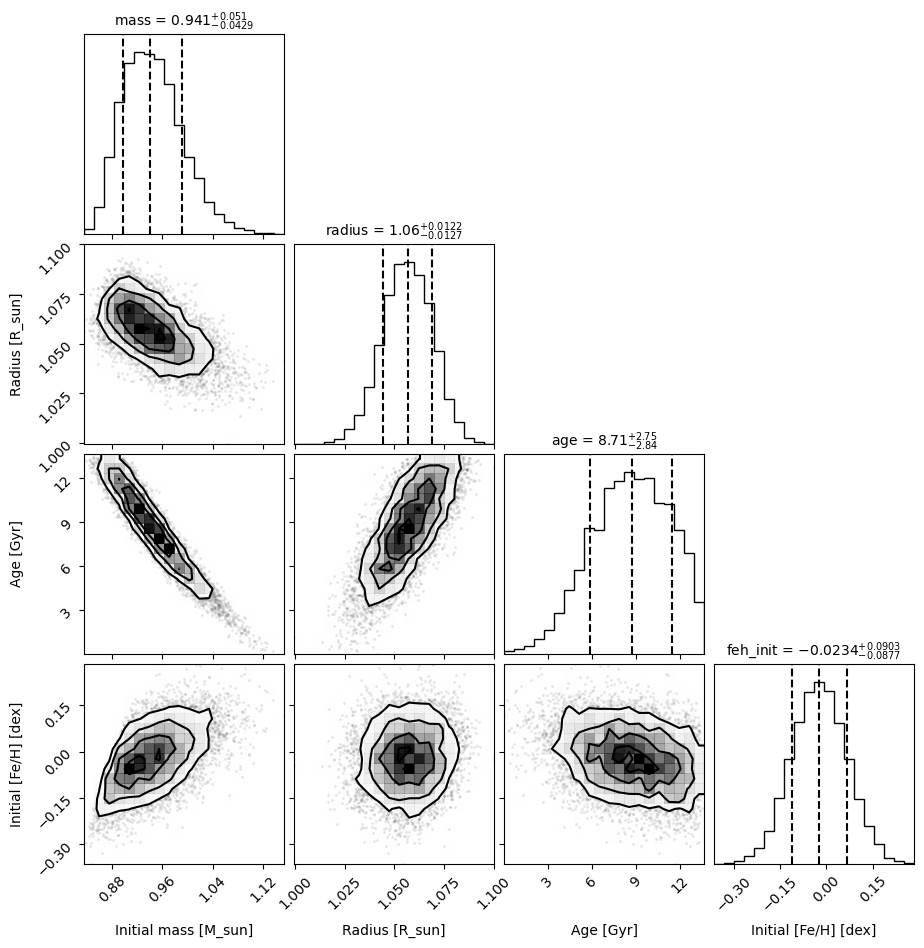

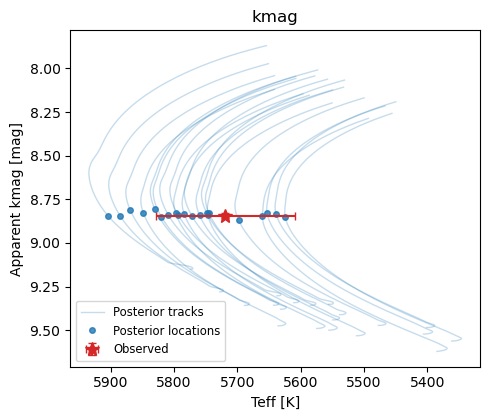

In [12]:
run_nested_sampling = True

if run_nested_sampling:
    from jaxstar.mistfit import get_run_metadata

    # Use a fresh directory for each independent run.
    mn_run_name = datetime.now().strftime("run_%Y%m%d_%H%M%S_%f")
    mn_dir = Path("results/track_multinest_v25") / mn_run_name
    mn = mf.run_multinest(
        outputfiles_basename=str(mn_dir / "run_"),
        model_kwargs=model_kwargs,
        n_live_points=1600,
        resume=False,
    )
    mn_idata = mf.to_inference_data(mn)
    mf.save_result(mn_idata, mn_dir)
    mn_figures = mf.plot_diagnostics(
        mn_idata, output_dir=mn_dir,
        keys=("mass", "radius", "age", "feh_init"),
    )
    print(get_run_metadata(mn_idata)["evidence"])
